In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [2]:
d1 = find_file("240422_TEMPOSO4_C10_W3_run1.DSC", exp_type="francklab_esr/romana") #cooling 283K-->253K
d2 = find_file("240422_TEMPOSO4_C10_W3_run2.DSC", exp_type="francklab_esr/romana") #heating subsequently 253K-->283K

In [3]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [4]:
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (10, 'harmonic')]

In [5]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [6]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (31, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in dodecane for cooling')

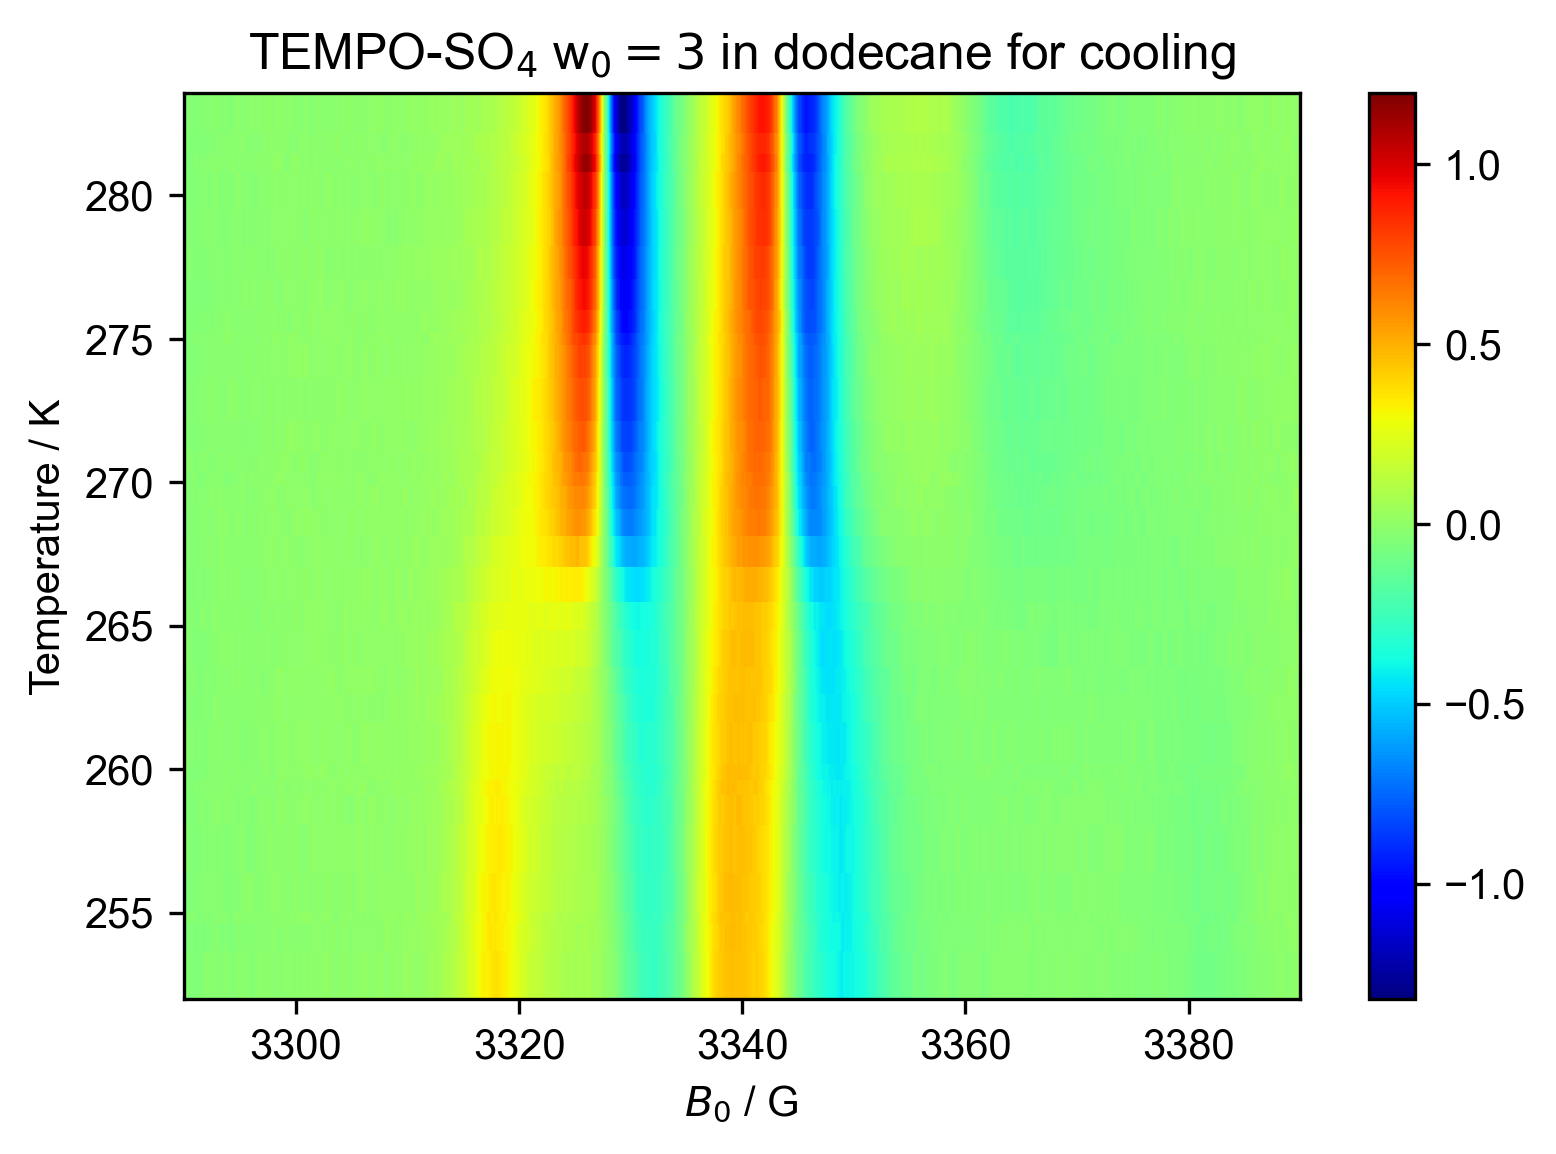

In [7]:
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1= d1['$B_0$':(3290,3390)]
d1.sort('Temperature')
d1.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in dodecane for cooling")

Text(0.5, 1.0, 'TEMPO-SO$_4$ w$_0= 3$ in dodecane for heating')

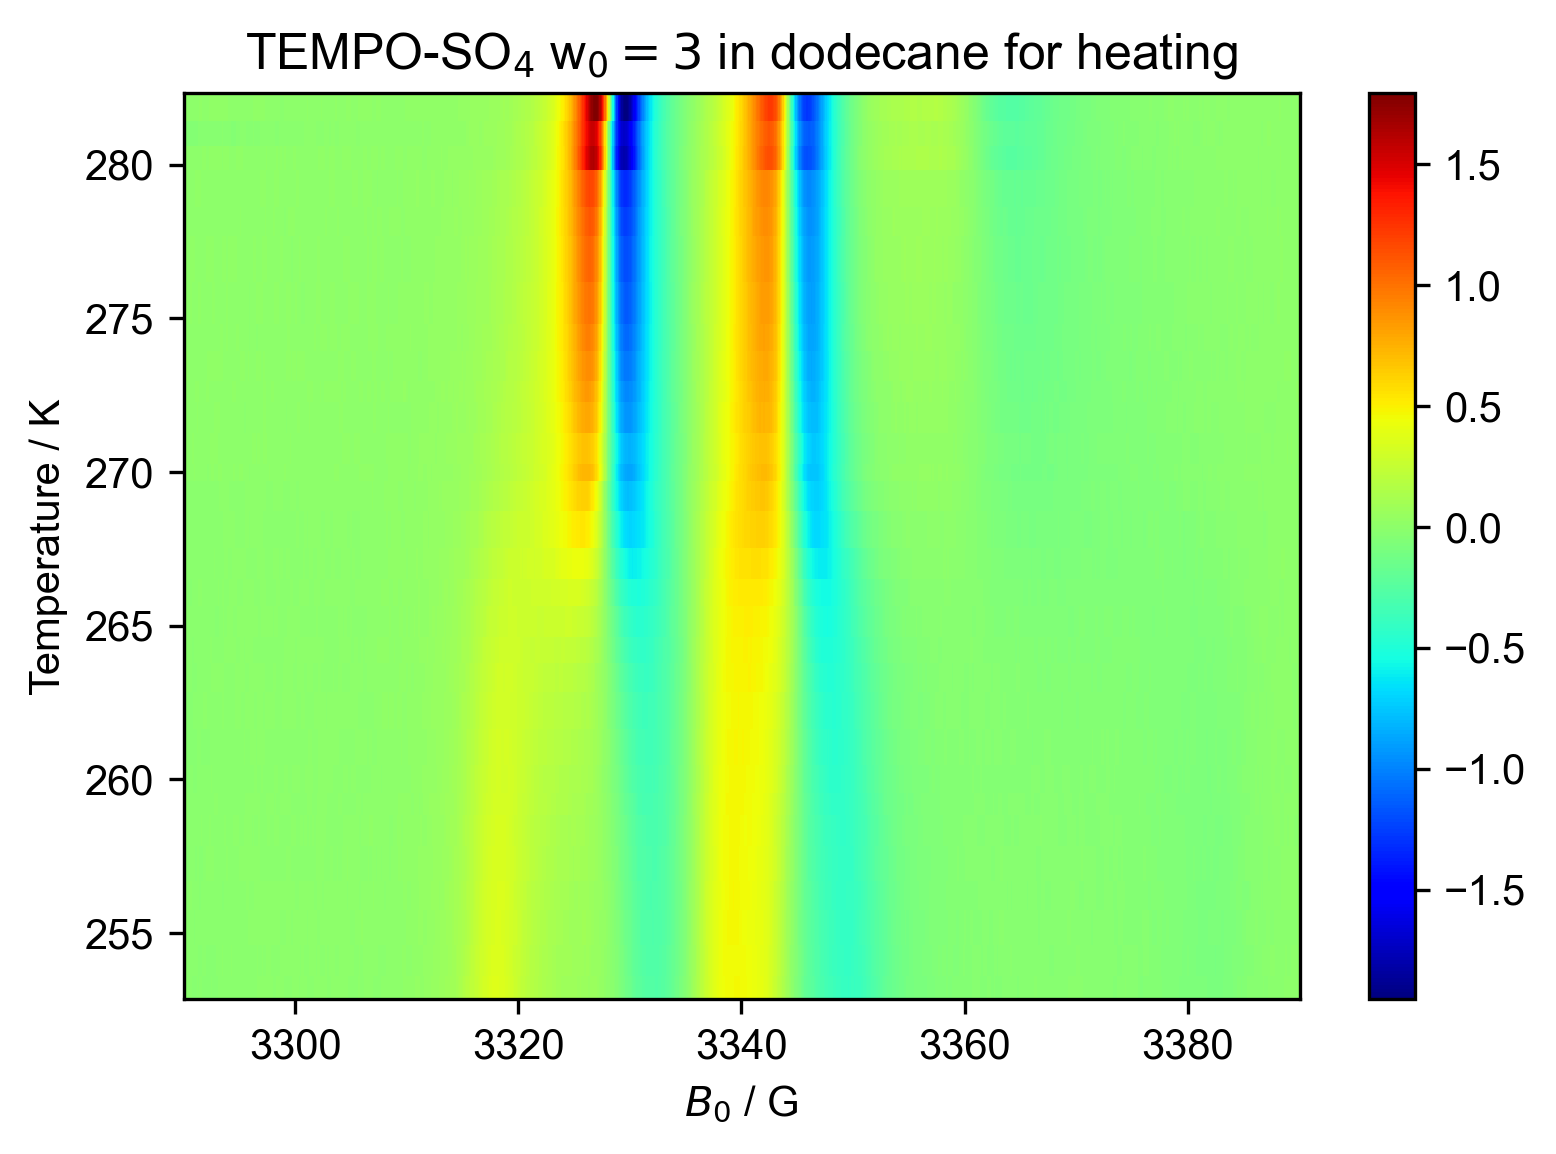

In [8]:
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2= d2['$B_0$':(3290,3390)]
d2.sort('Temperature')
d2.reorder("Temperature").pcolor()
title("TEMPO-SO$_4$ w$_0= 3$ in dodecane for heating")

From this, I learn that
it's easiest to show the 1D plots above and below the transition

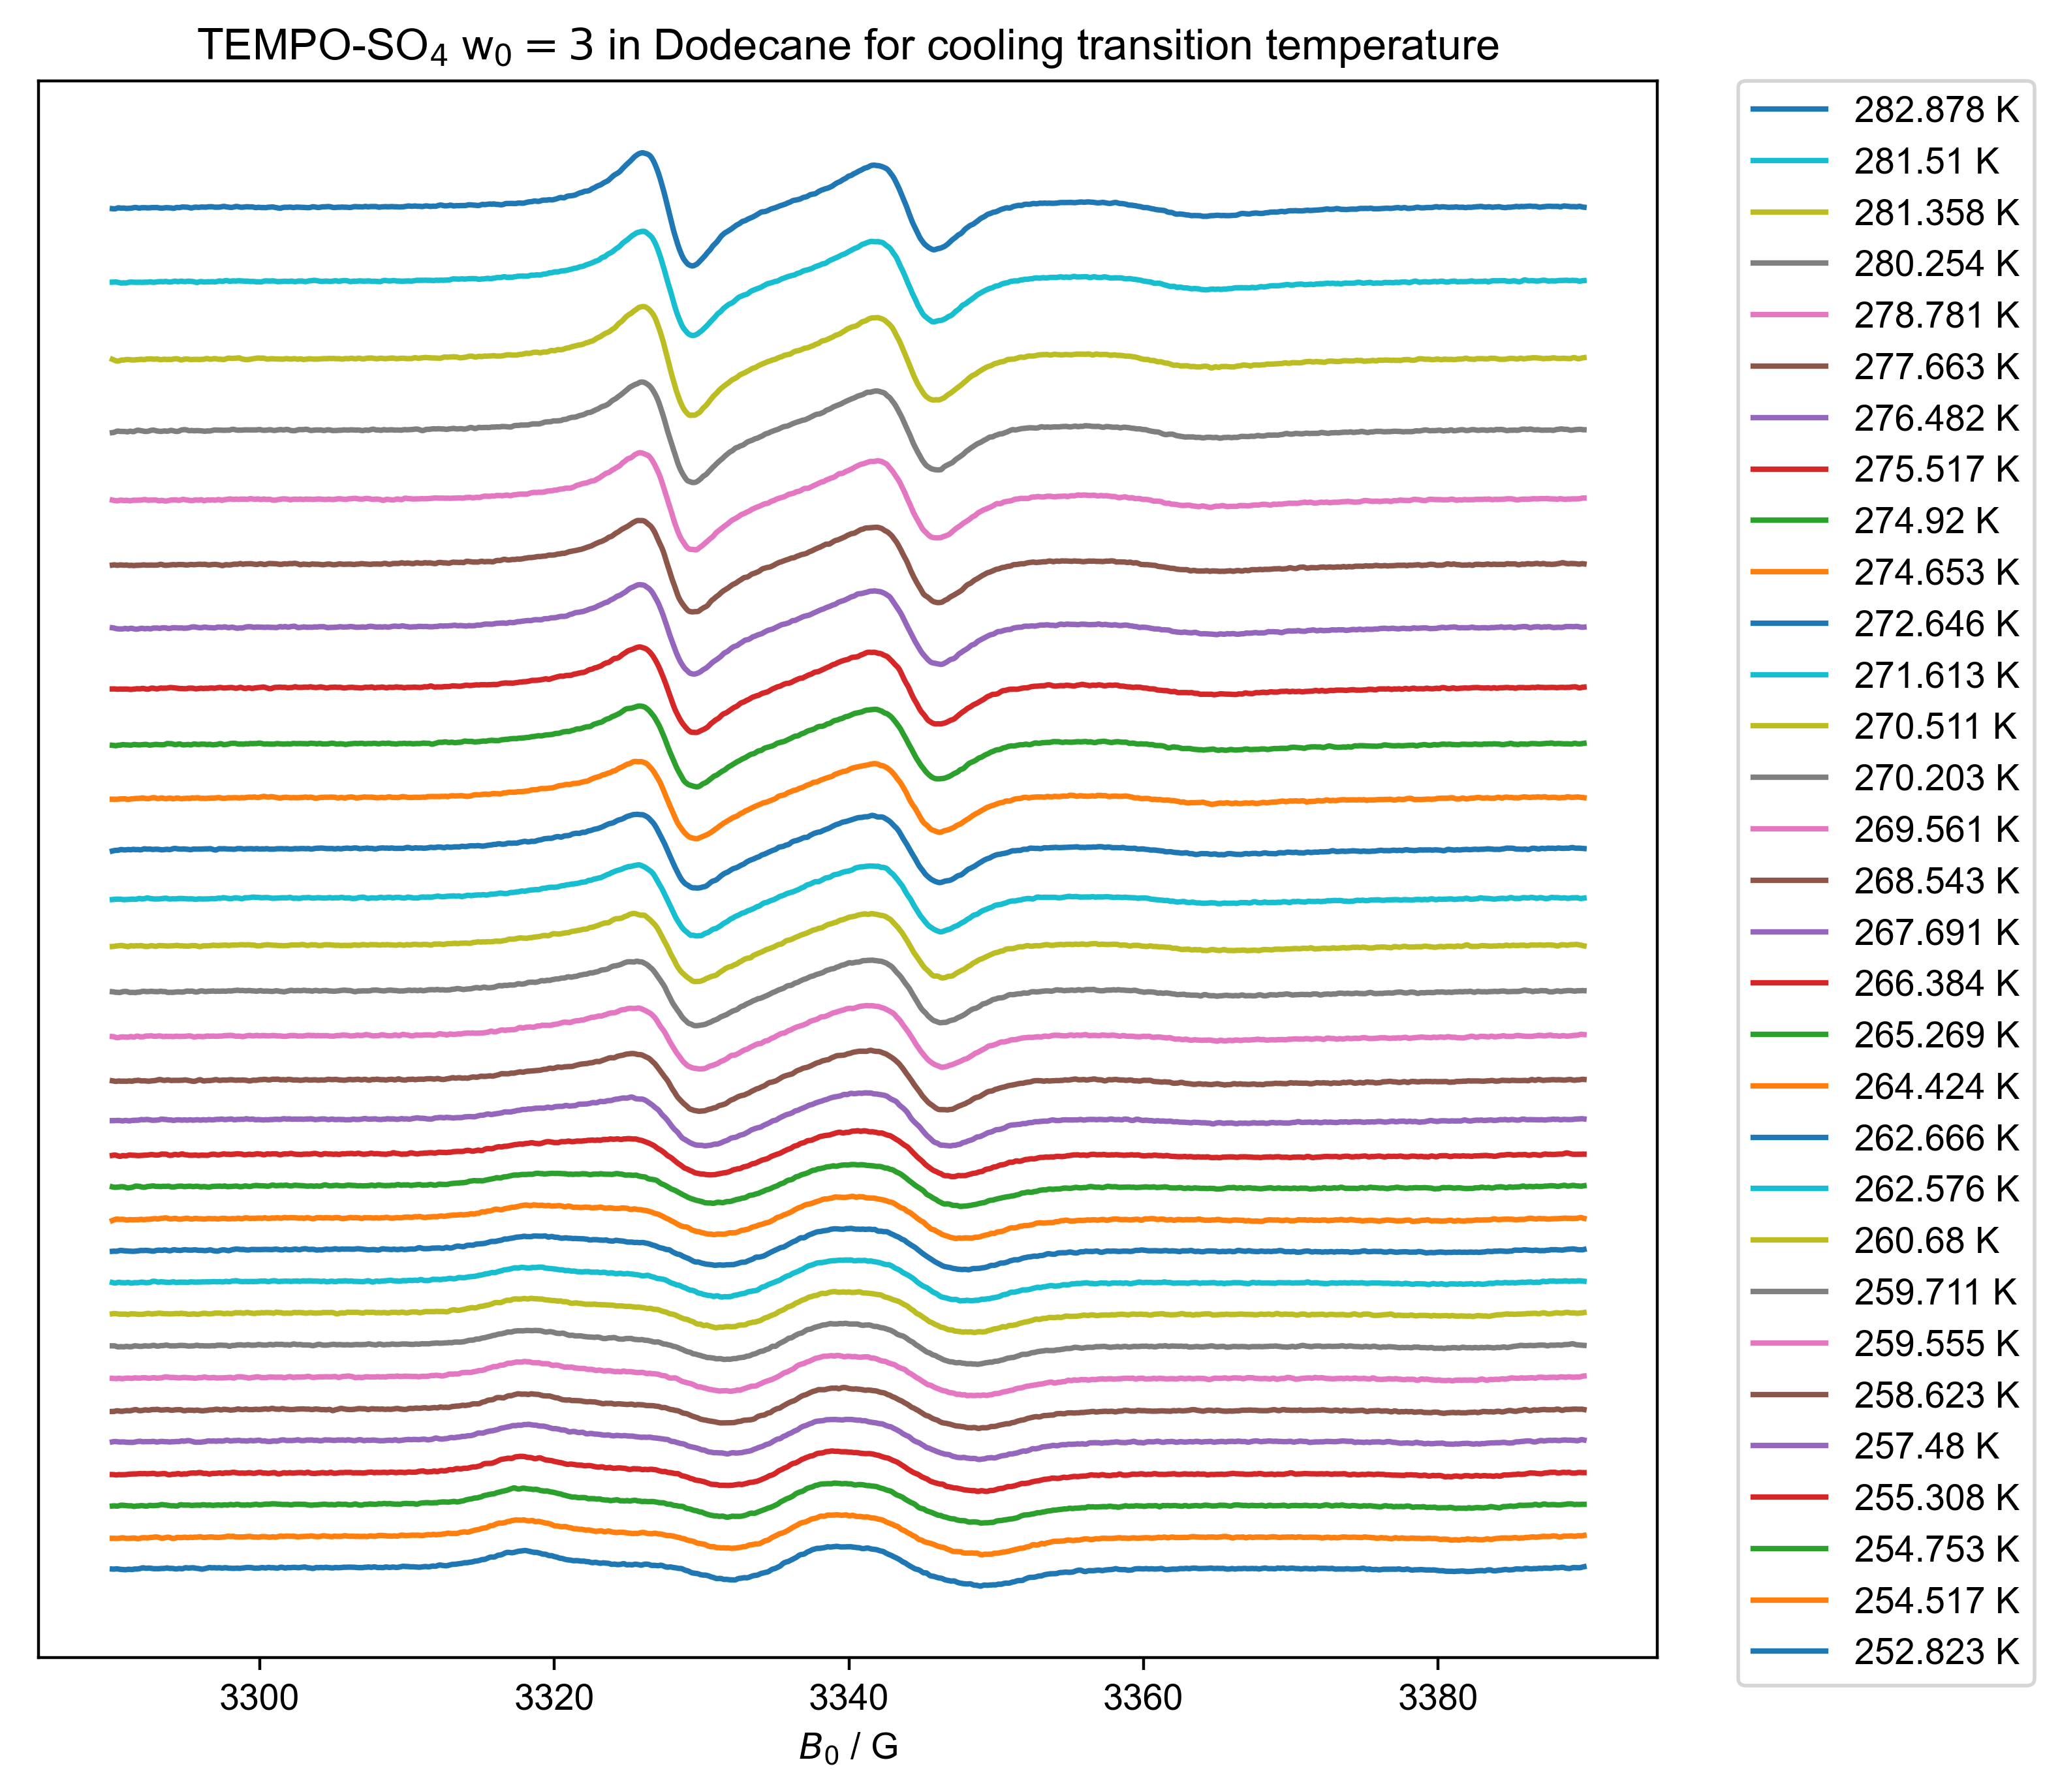

In [9]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for cooling transition temperature", (173, 373))
 ]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 20
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
#     fancy_legend()

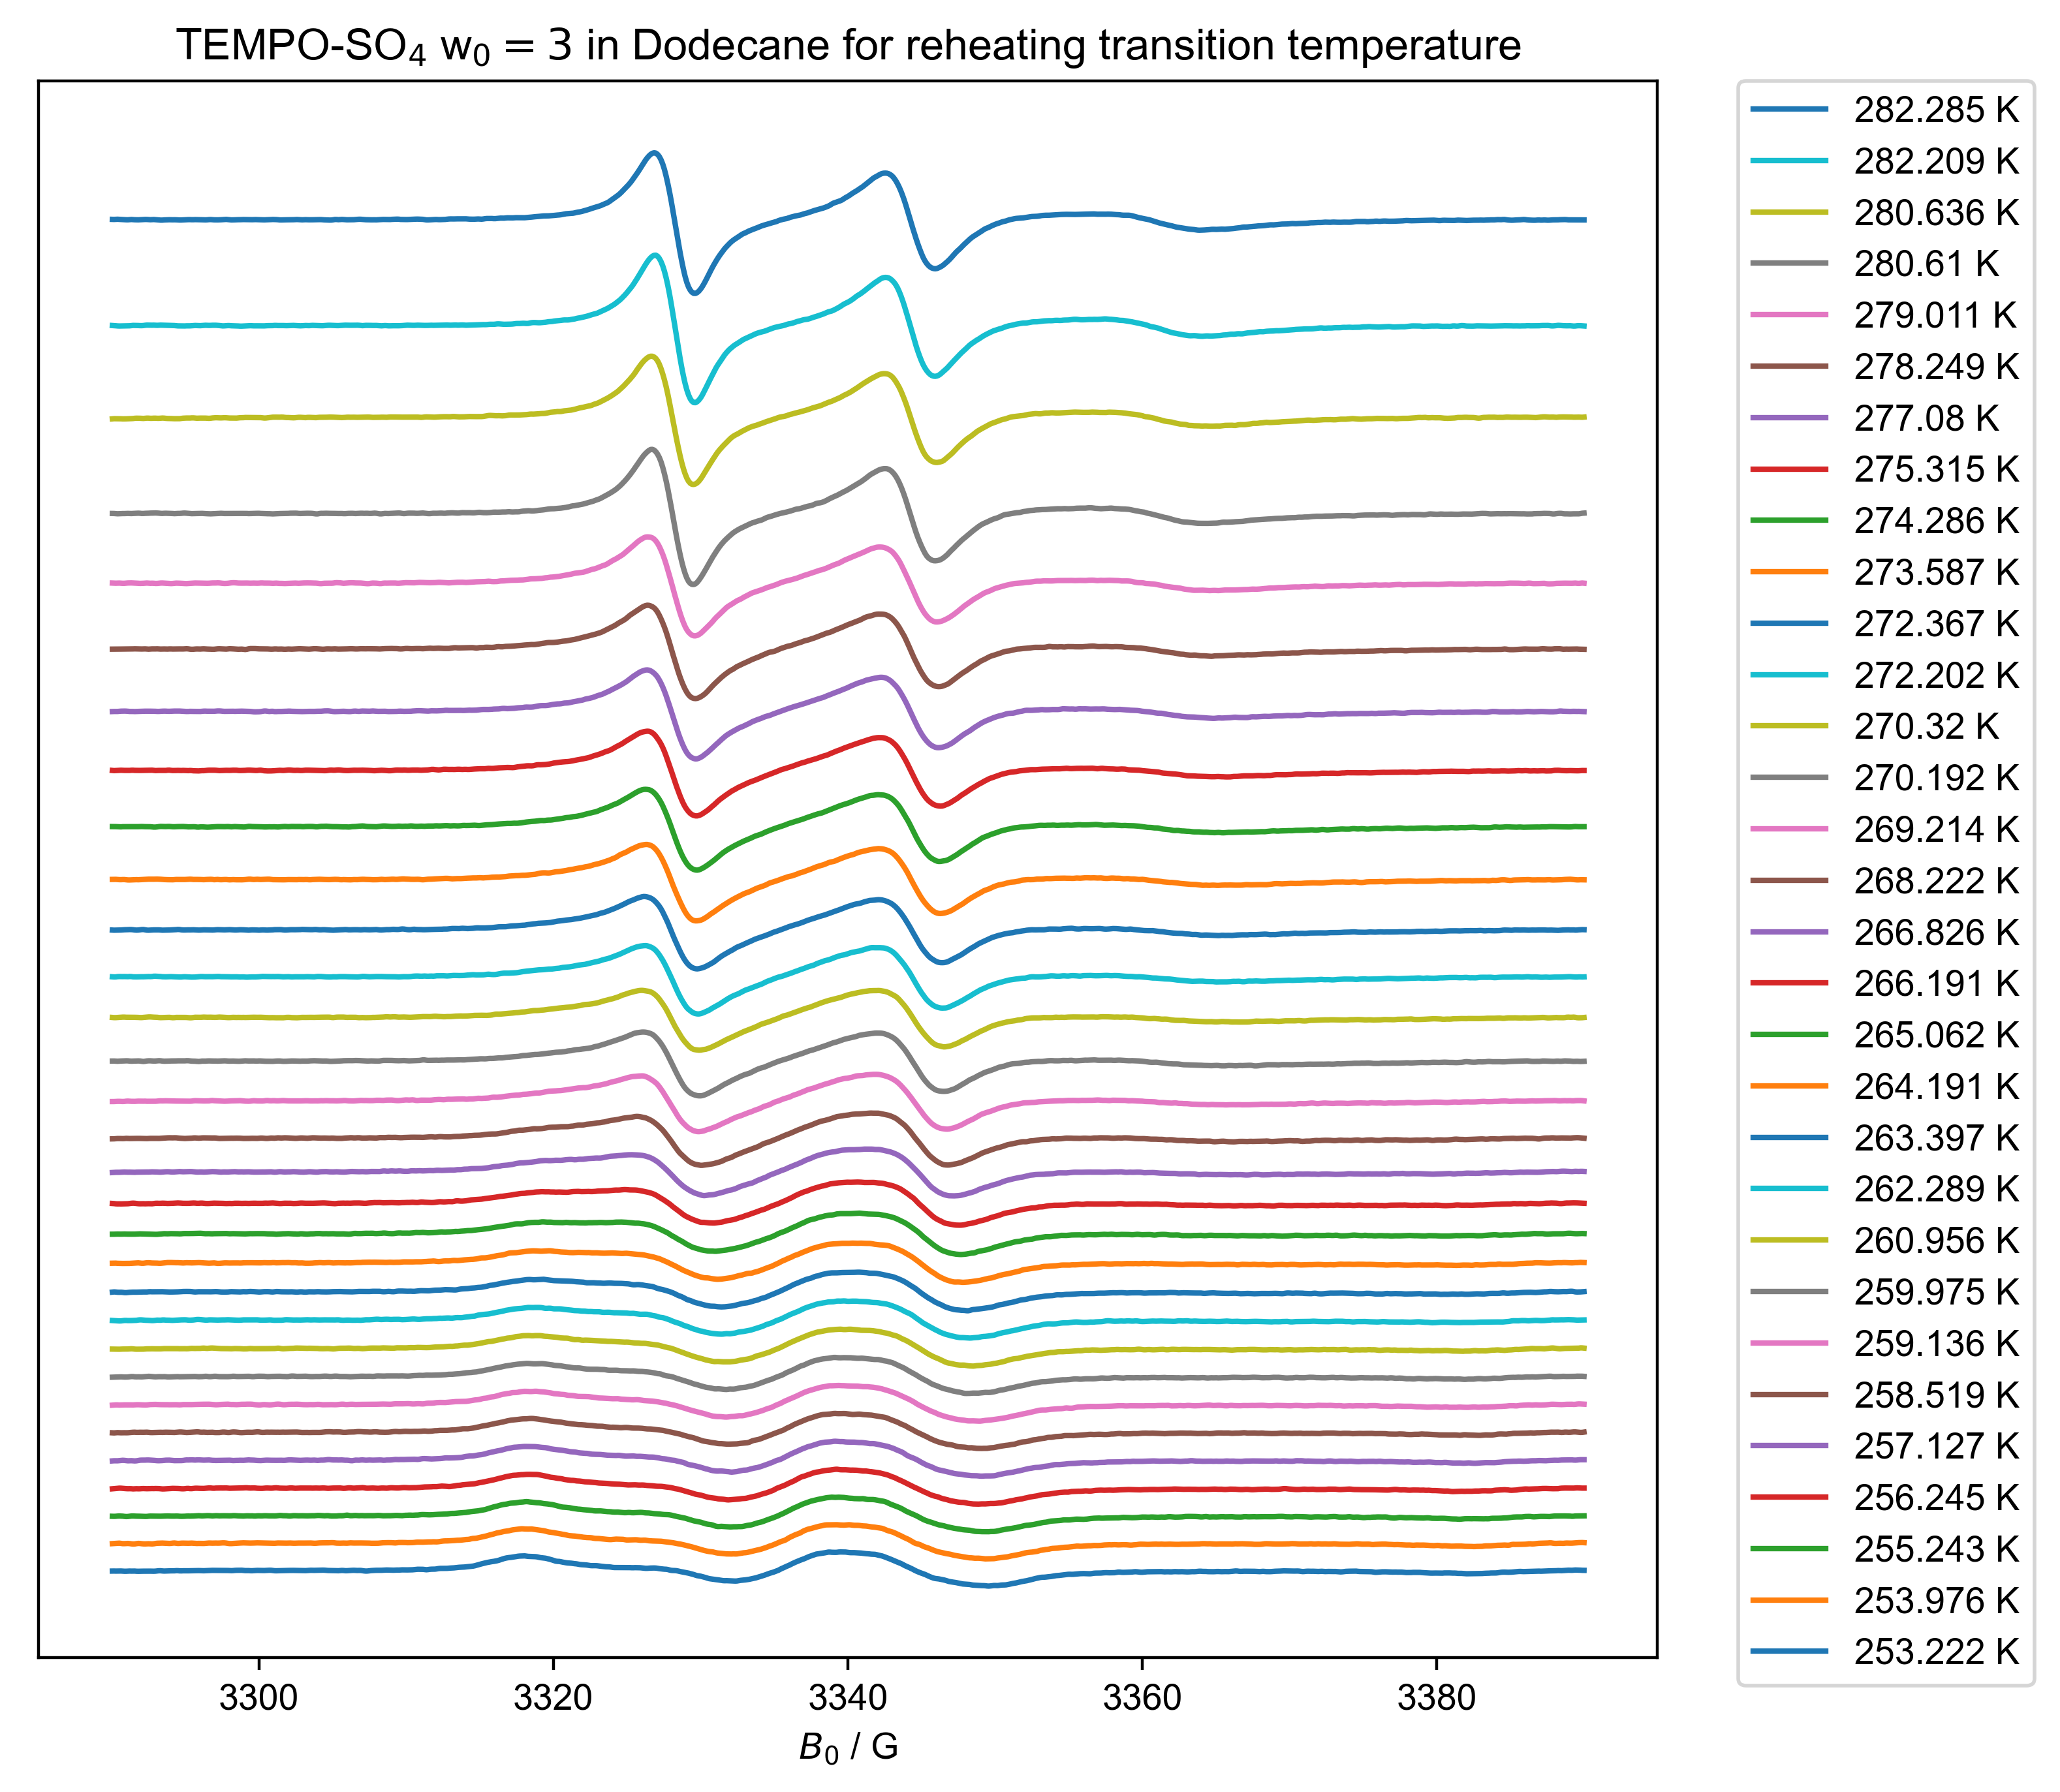

In [10]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("TEMPO-SO$_4$ w$_0= 3$ in Dodecane for reheating transition temperature", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=400, figsize=(8,8)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
#         offset += 20
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        
        # Get handles and labels
        handles, labels = plt.gca().get_legend_handles_labels()
        # Reverse the order of handles and labels
        handles.reverse()
        labels.reverse()
        # Create the legend with reversed order and place it outside of the plot
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

        
#     fancy_legend()

[252.823 254.517 254.753 255.308 257.48  258.623 259.555 259.711 260.68
 262.576 262.666 264.424 265.269 266.384 267.691 268.543 269.561 270.203
 270.511 271.613 272.646 274.653 274.92  275.517 276.482 277.663 278.781
 280.254 281.358 281.51  282.878]
[253.222 253.976 255.243 256.245 257.127 258.519 259.136 259.975 260.956
 262.289 263.397 264.191 265.062 266.191 266.826 268.222 269.214 270.192
 270.32  272.202 272.367 273.587 274.286 275.315 277.08  278.249 279.011
 280.61  280.636 282.209 282.285]


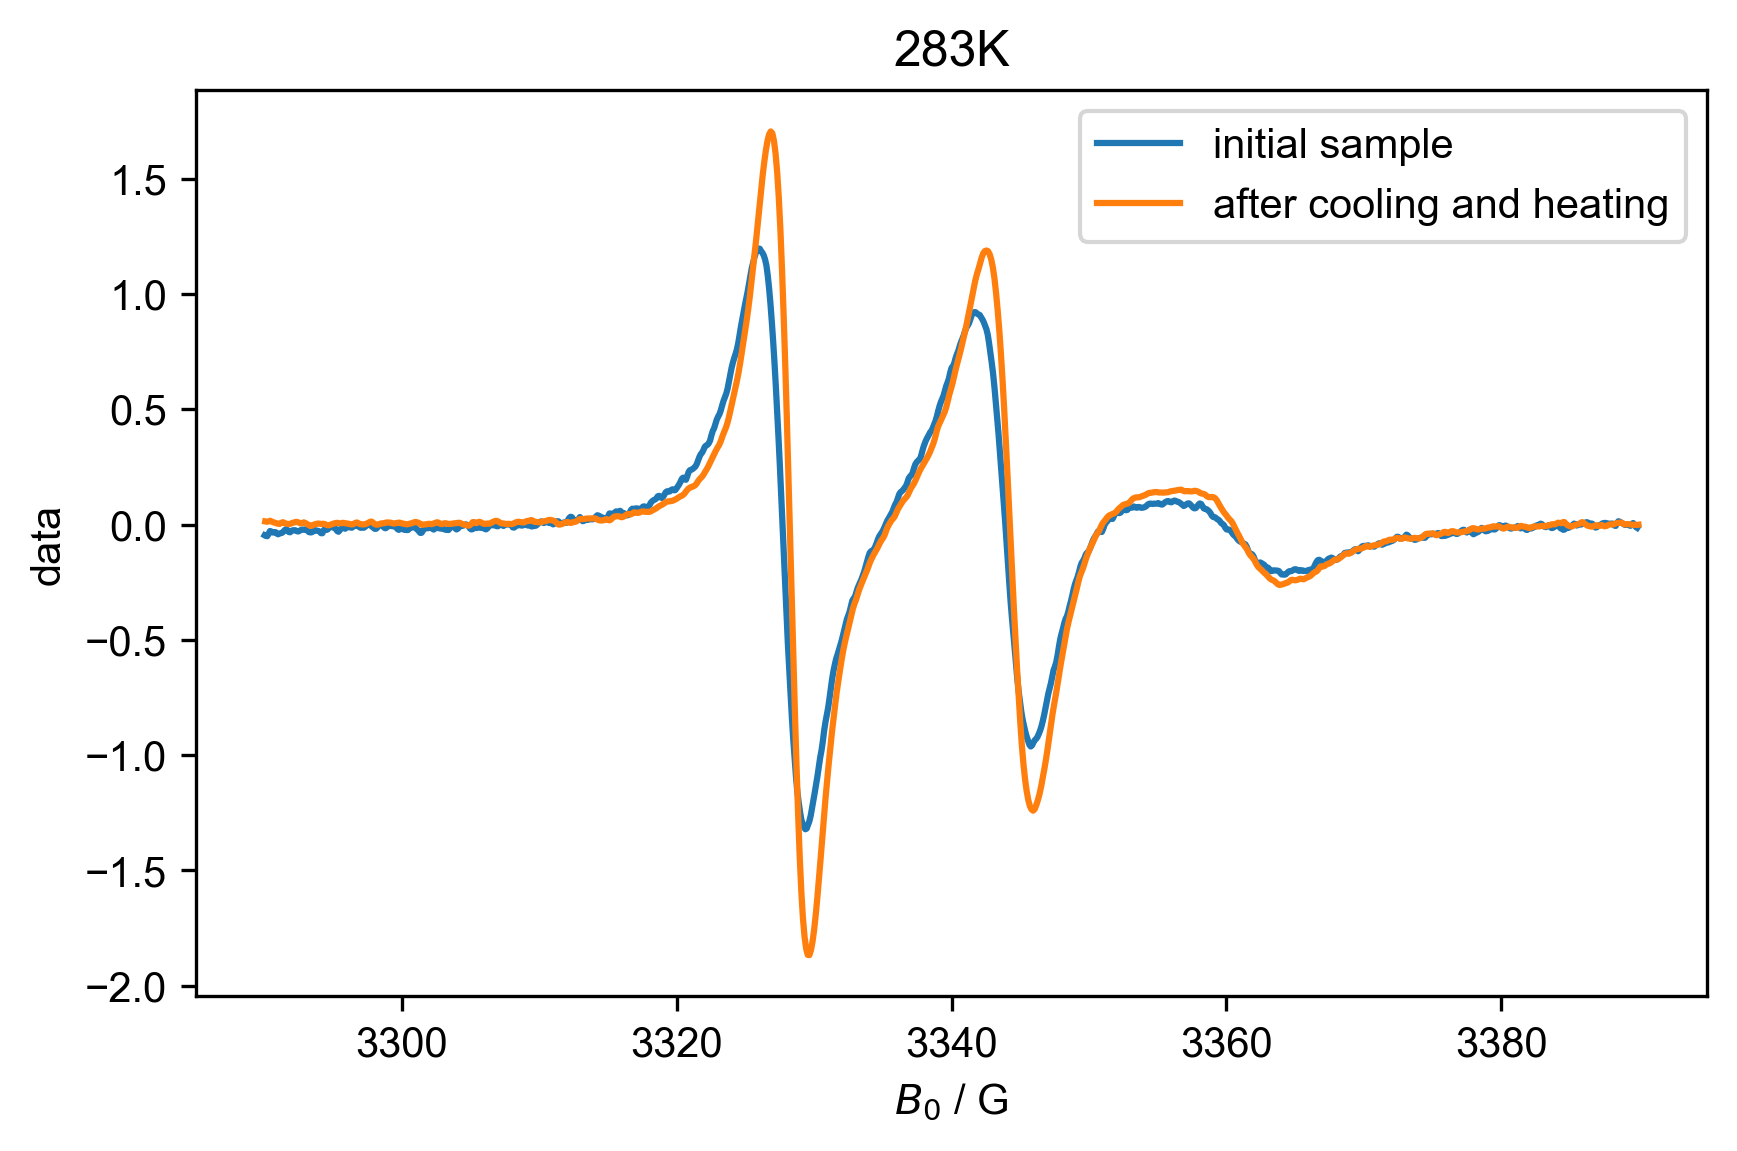

In [11]:
#near room temperature
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6.5,4))
plot(d1["Temperature":283], label="initial sample")
plot(d2["Temperature":283], label="after cooling and heating")
title("283K")
# title("TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

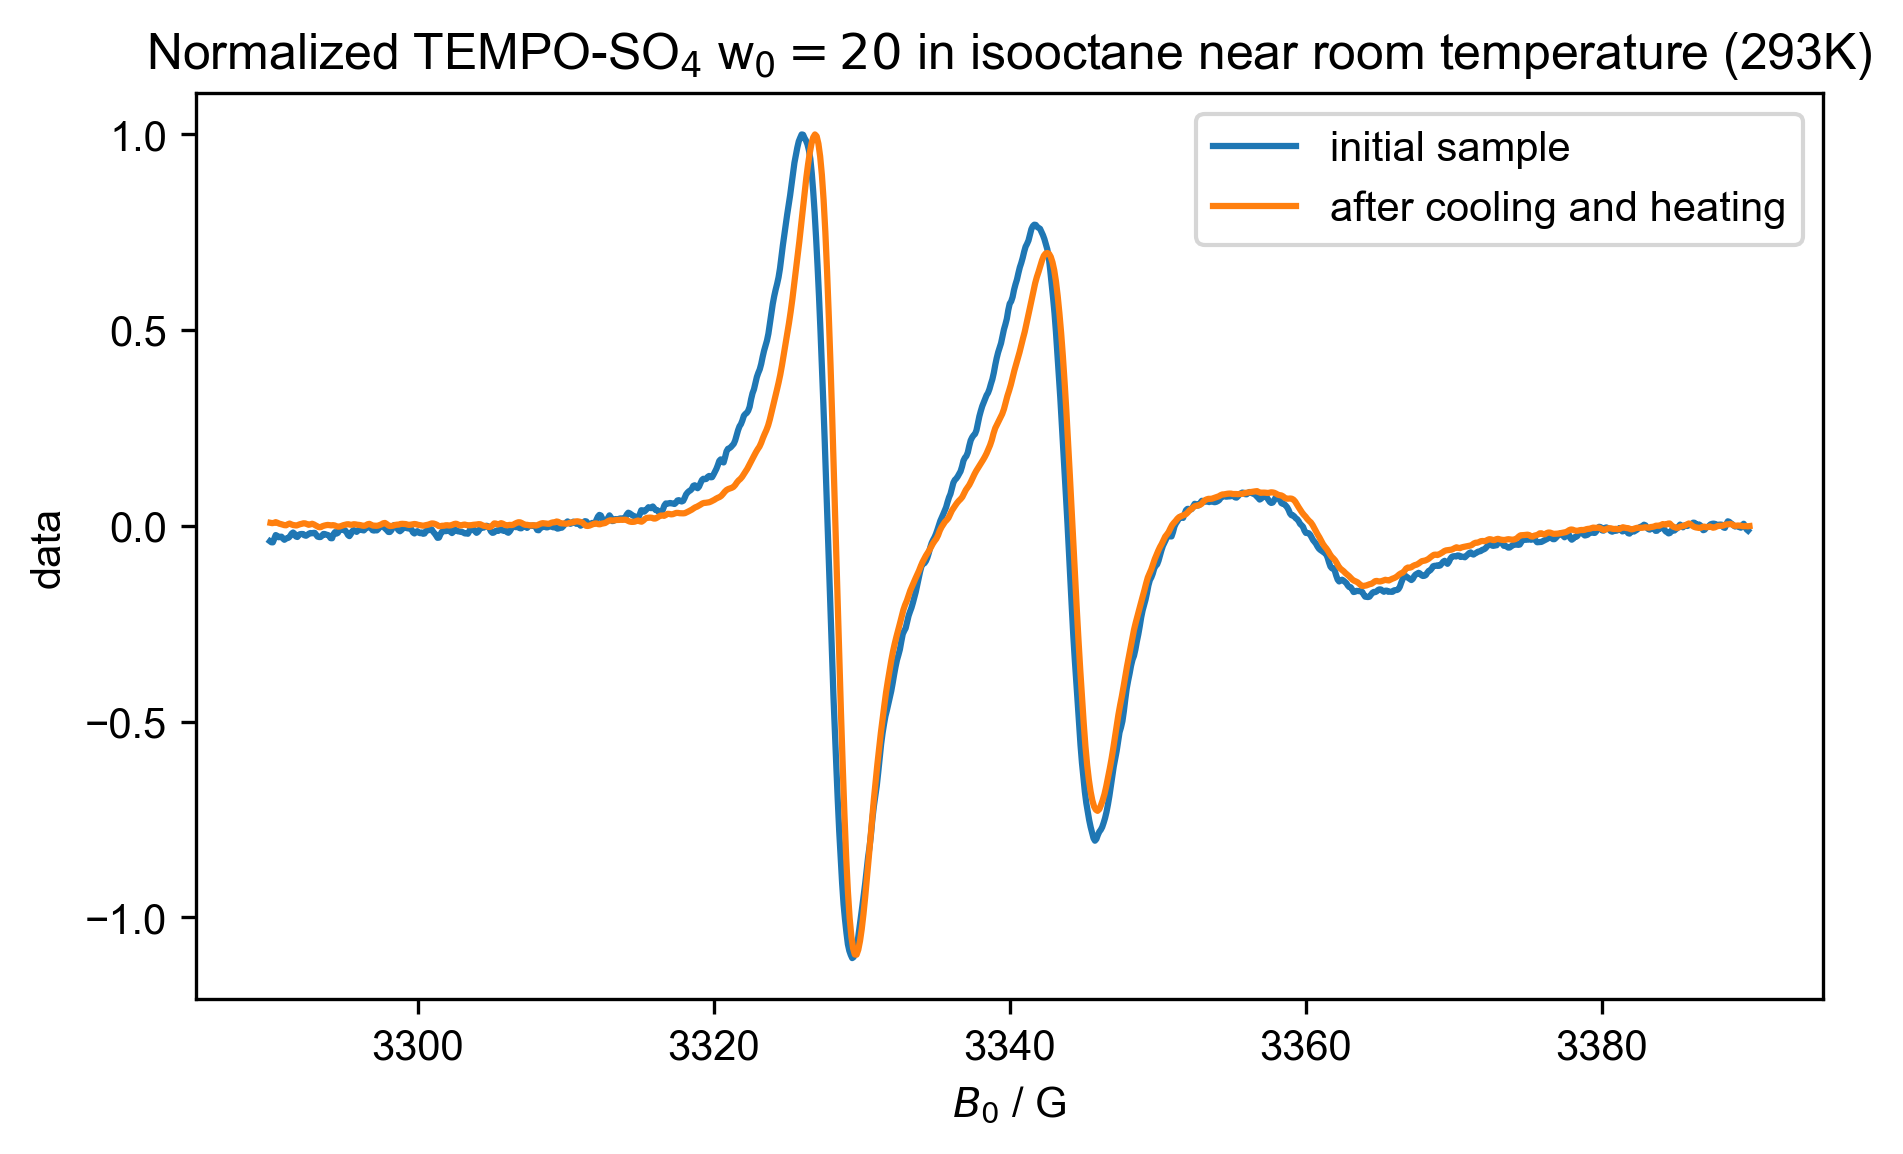

In [12]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "initial sample")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "after cooling and heating")
title("Normalized TEMPO-SO$_4$ w$_0= 20$ in isooctane near room temperature (293K)")
legend()

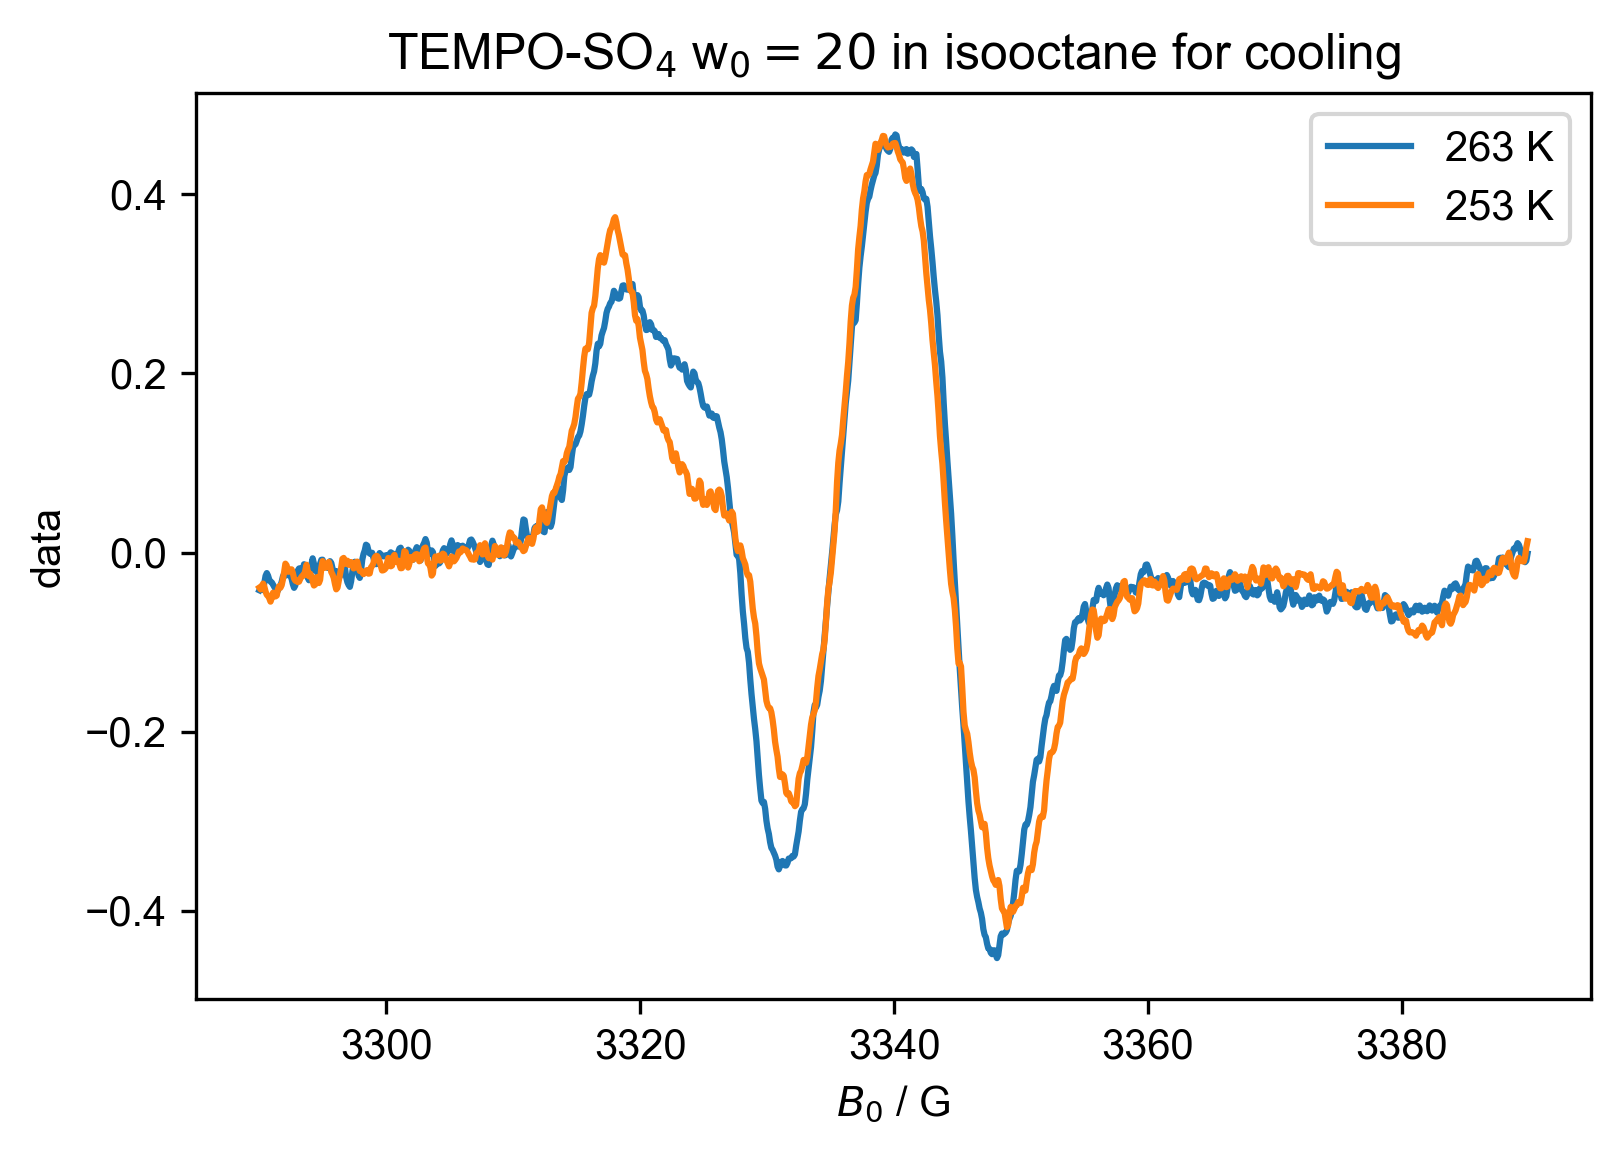

In [13]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="263 K")
plot(d1["Temperature":253], label="253 K")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane for cooling")
legend()

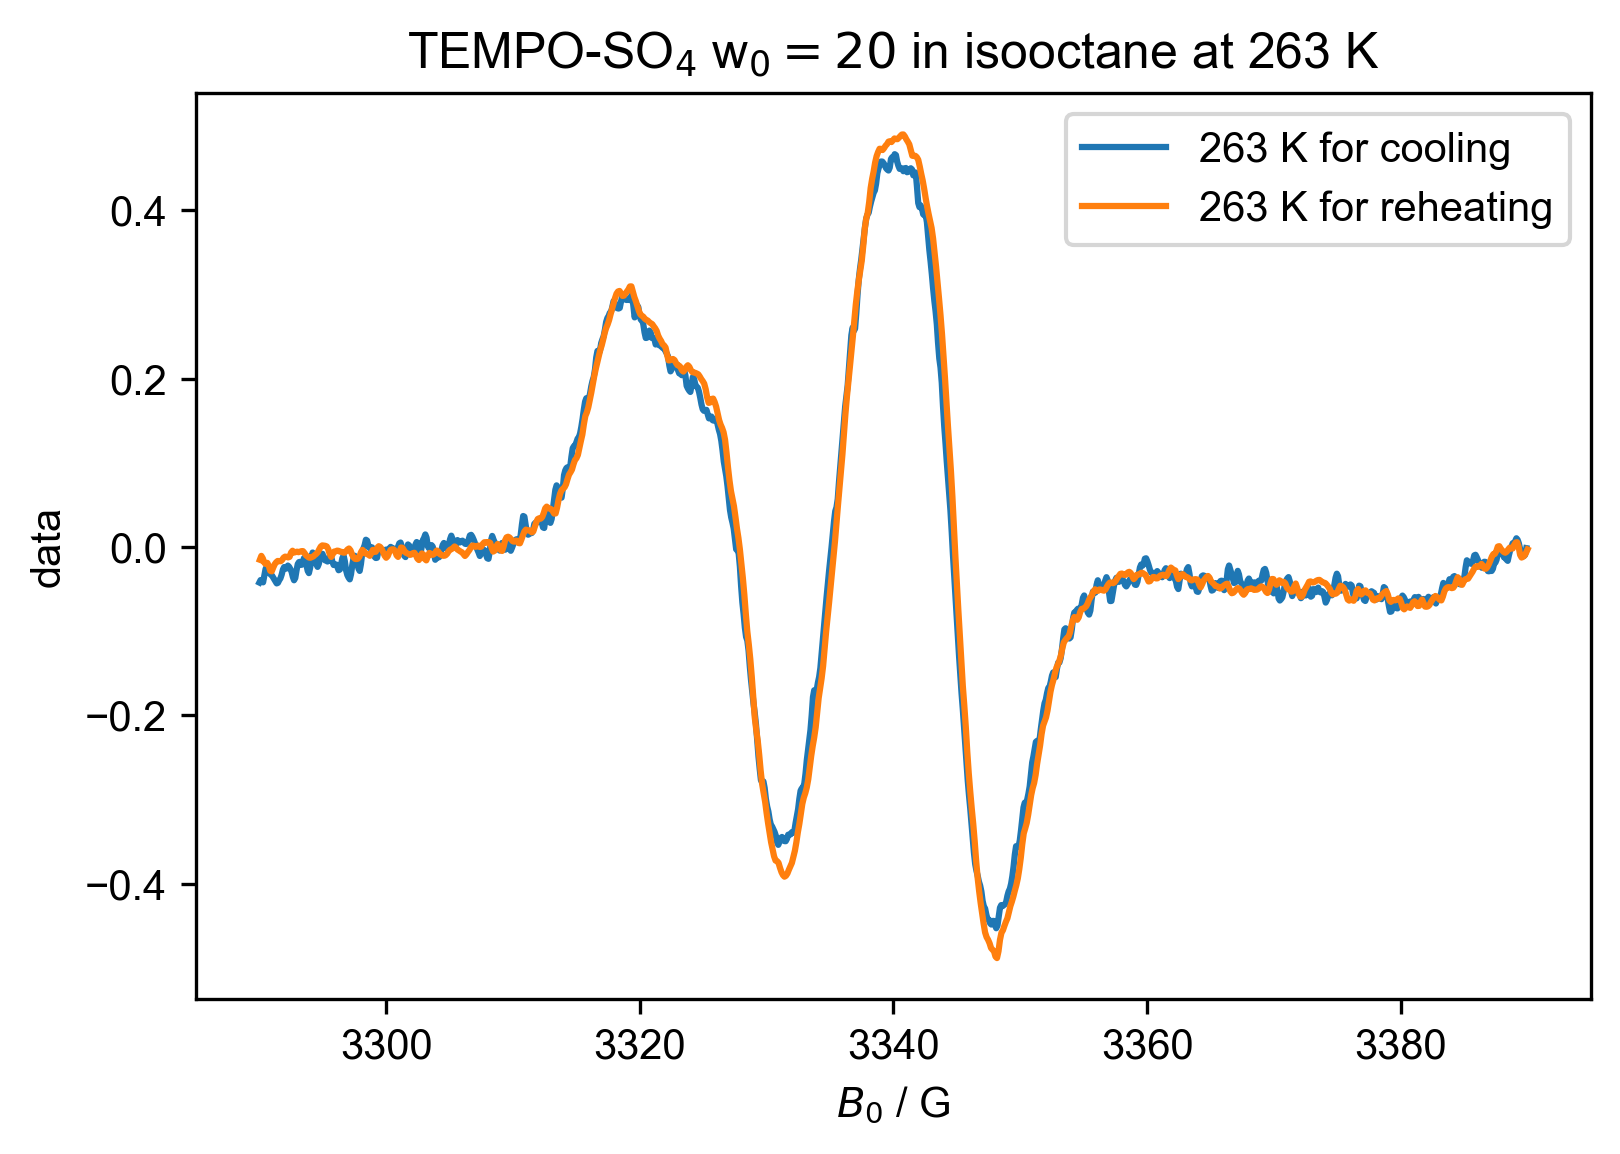

In [14]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":263], label="263 K for cooling")
plot(d2["Temperature":263], label="263 K for reheating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane at 263 K")
legend()

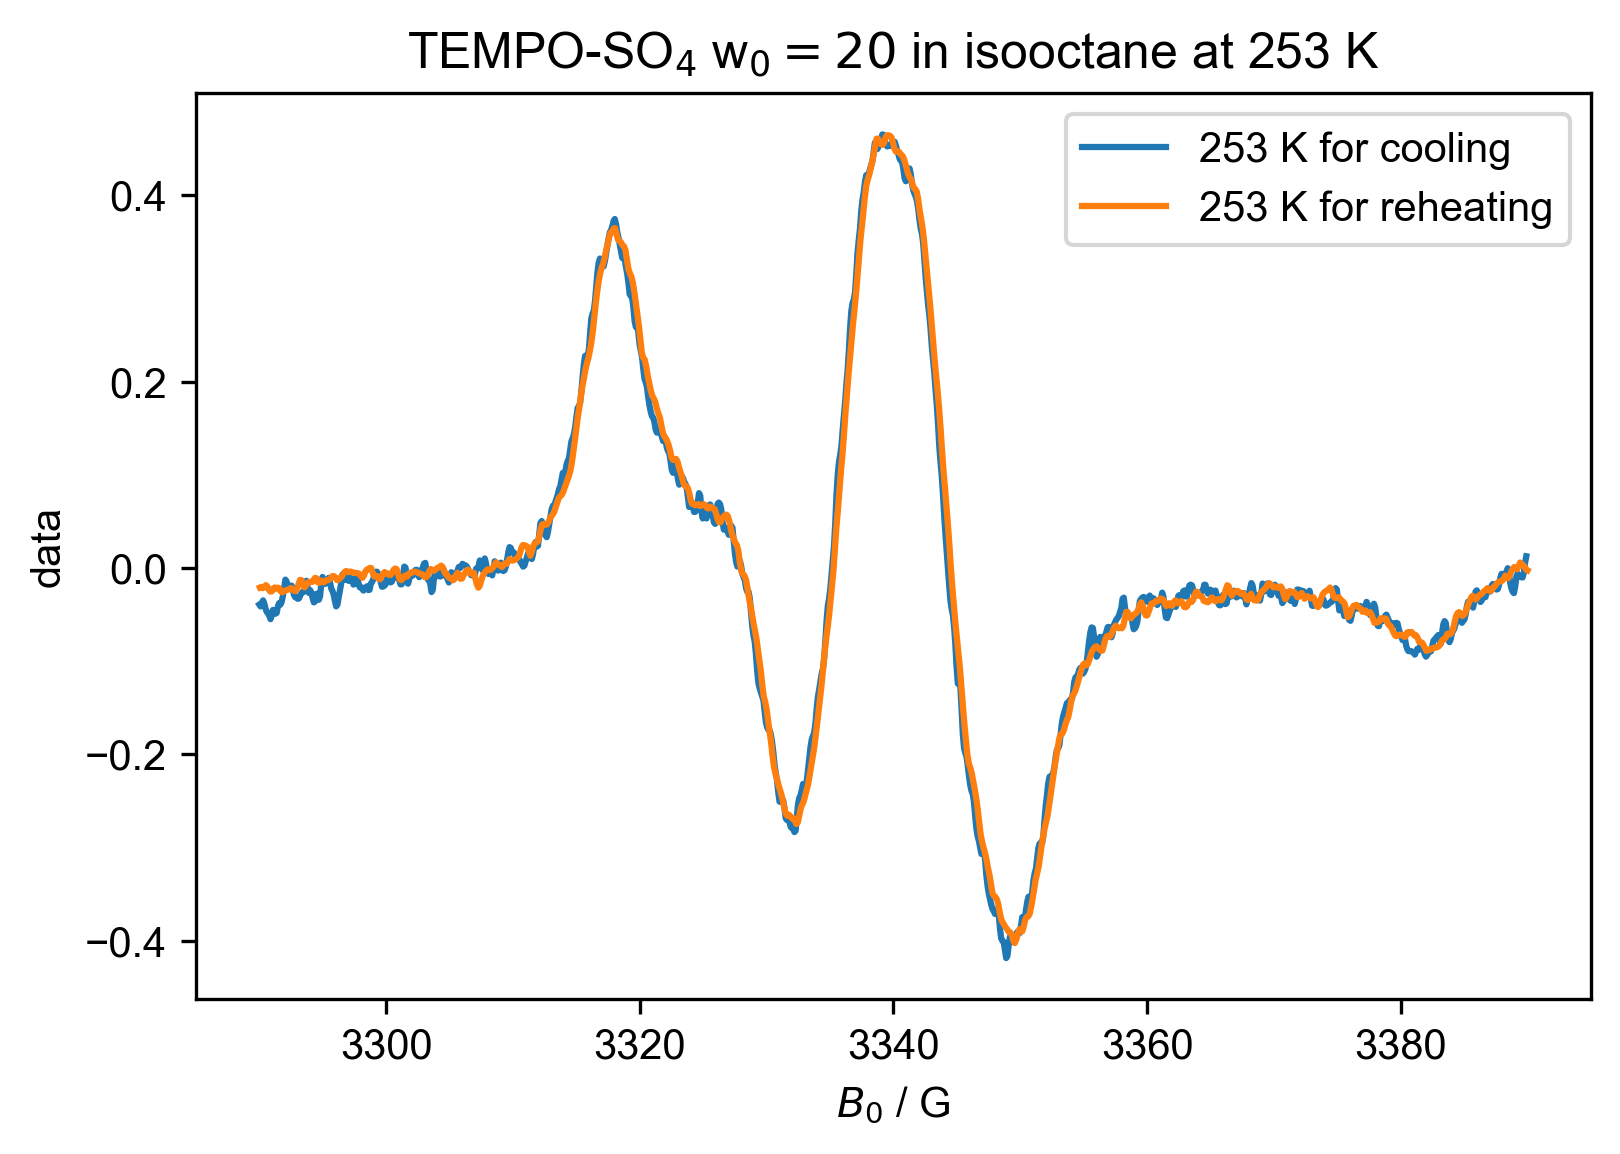

In [15]:
# Water shedding
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":253], label="253 K for cooling")
plot(d2["Temperature":253], label="253 K for reheating")
title("TEMPO-SO$_4$ w$_0= 20$ in isooctane at 253 K")
legend()